# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


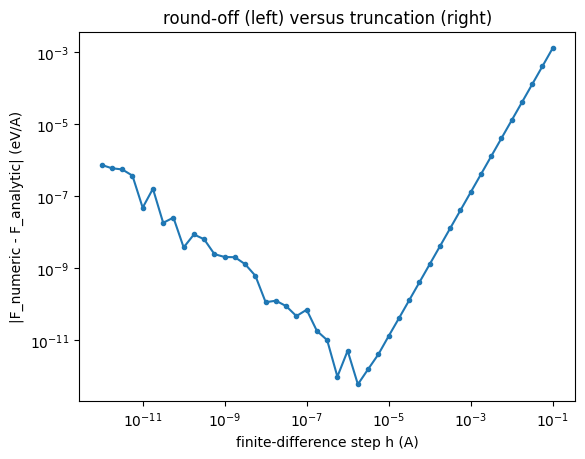

In [1]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

[Forward Difference] Best step h = 1.0e-08 A, error = 5.5e-10 eV/A


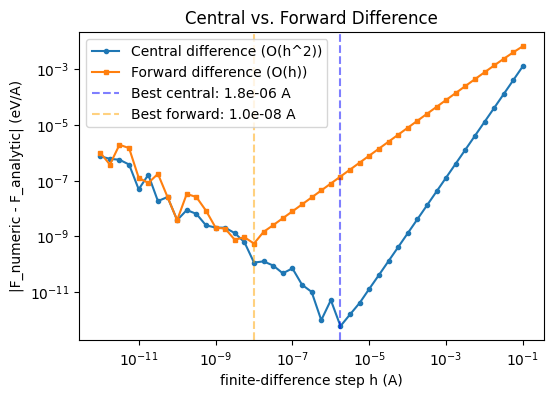

In [10]:
# Exercise 1
# Theory: h_opt ~ eps_mach^(1/3) * L
# eps_mach^(1/3) is about 6e-6. If I take L = sigma = 3.4 A, I get h_opt ~ 2e-5 A,
# which is about 10 times bigger than the h I found (1.8e-6 A).
# A better length scale is L = (U / third derivative of U)^(1/3), since truncation error depends on it.
# For LJ at r = 3.6 A this L is about 0.3 A, and then h_opt ~ 2e-6 A, which matches.

# r was changed to an array in Exercise 2, so I use a new variable here
r_scalar = 3.6

# 2. Repeat with forward difference:
err_forward = [abs(-(U(r_scalar + h) - U(r_scalar)) / h - F(r_scalar)) for h in hs]
best_forward = hs[np.argmin(err_forward)]
print(f"[Forward Difference] Best step h = {best_forward:.1e} A, error = {min(err_forward):.1e} eV/A")

plt.figure(figsize=(6, 4))
plt.loglog(hs, err, "o-", ms=3, label="Central difference (O(h^2))")
plt.loglog(hs, err_forward, "s-", ms=3, label="Forward difference (O(h))")
plt.axvline(best, color="blue", ls="--", alpha=0.5, label=f"Best central: {best:.1e} A")
plt.axvline(best_forward, color="orange", ls="--", alpha=0.5, label=f"Best forward: {best_forward:.1e} A")
plt.xlabel("finite-difference step h (A)")
plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.legend()
plt.title("Central vs. Forward Difference")
plt.show()

**Exercise 1 answer**

**Central difference:** The best step I got is $h \approx 1.8\times10^{-6}$ Å. If I use $\sigma = 3.4$ Å as the length scale, the formula $\varepsilon_{\rm mach}^{1/3}\sigma$ gives about $2\times10^{-5}$ Å, so it is around 10 times larger than my result. The order is not far, but the length scale $\sigma$ is too big. The truncation error depends on $U^{(3)}$, and the LJ potential changes very fast ($r^{-12}$), so the real length scale is $(U/U^{(3)})^{1/3} \approx 0.3$ Å. With this value the formula gives $h \approx 2\times10^{-6}$ Å, which agrees well with what I found.

**Forward difference:** The best step is $h \approx 1\times10^{-8}$ Å with error $\approx 5.5\times10^{-10}$ eV/Å. This is about 1000 times worse than the central difference ($5.9\times10^{-13}$ eV/Å).

The reason is that the forward difference has truncation error $\propto h$ (first order), but the central difference has error $\propto h^2$. So for the forward difference the truncation error is bigger at the same $h$, and we have to go to a much smaller $h$ (theory: $h \sim \sqrt{\varepsilon_{\rm mach}}$). But at small $h$ the round-off error $\varepsilon_{\rm mach}/h$ becomes large, so the best error we can reach is much worse.

(Note: near the minimum the error curve is noisy because of round-off, so the exact best $h$ can change a little.)

---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


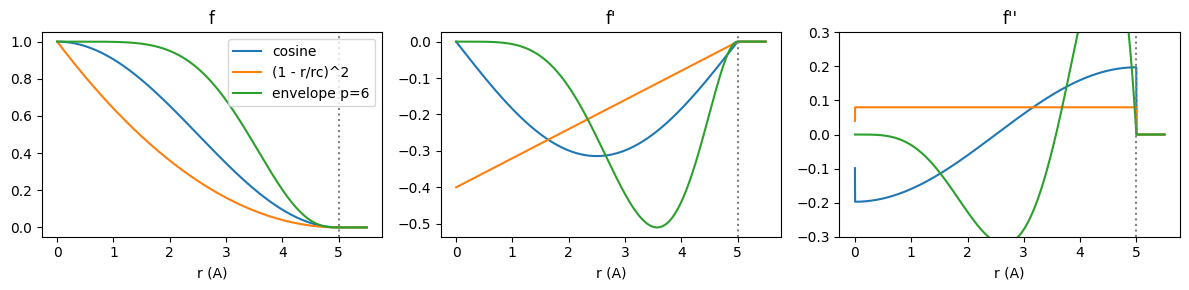

In [2]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

**Exercise 2 answer**

**Ranking (smoothest first):**
1. Envelope $p=6$: $f$, $f'$ and $f''$ are all zero at $r_c$. (The printed $f''=0.013$ is not exactly 0 only because it is taken a few grid points inside $r_c$; analytically $f''(r_c)=0$.)
2. $(1-r/r_c)^2$: $f=0$, $f'=0$, but $f''=2/r_c^2=0.08$, so the curvature jumps at $r_c$.
3. Cosine: $f=0$, $f'=0$, but $f''=\tfrac12(\pi/r_c)^2\approx0.20$, the biggest jump.

**Which property is affected:** The phonon frequencies. The phonons come from the Hessian, which is the second derivative of the energy. If $f''$ jumps at $r_c$, then the Hessian also jumps when a neighbour crosses $r_c$, so the phonon frequencies and elastic constants can have small errors or jumps.

Energy conservation in MD is mostly fine, because MD only needs the energy and the forces (first derivative) to be continuous, and all three cutoffs give that.

---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


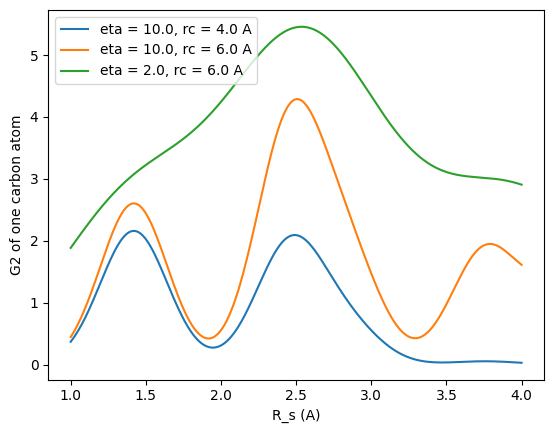

In [3]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

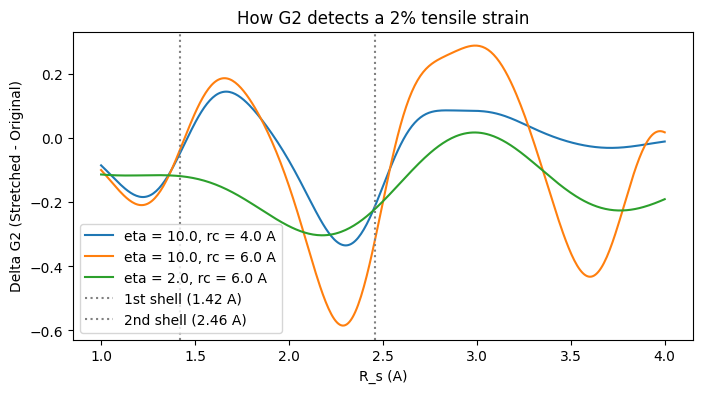

In [6]:
# Exercise 3:
# Stretch the lattice by 2%
d_stretched = 1.42 * 1.02
a1_s, a2_s = d_stretched * np.array([1.5, np.sqrt(3) / 2]), d_stretched * np.array([1.5, -np.sqrt(3) / 2])
atoms_s = np.array([i * a1_s + j * a2_s + b * (d_stretched / d) for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre_s = atoms_s[np.argmin(np.linalg.norm(atoms_s, axis=1))]
r0j_s = np.linalg.norm(atoms_s - centre_s, axis=1); r0j_s = r0j_s[r0j_s > 1e-6]

plt.figure(figsize=(8, 4))
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2_orig = np.array([np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs])
    G2_stretching = np.array([np.sum(np.exp(-eta * (r0j_s - s)**2) * fc(r0j_s, rc)) for s in Rs])
    plt.plot(Rs, G2_stretching - G2_orig, label=f"eta = {eta}, rc = {rc} A")

plt.axvline(1.42, color="gray", ls=":", label="1st shell (1.42 A)")
plt.axvline(2.46, color="gray", ls=":", label="2nd shell (2.46 A)")
plt.xlabel("R_s (A)")
plt.ylabel("Delta G2 (Stretched - Original)")
plt.title("How G2 detects a 2% tensile strain")
plt.legend()
plt.show()

**Exercise 3 answer**

When the lattice is stretched by 2%, every neighbour moves further away, so each peak of $G^2$ moves to a larger $R_s$. That is why $\Delta G^2$ is negative just before a shell and positive just after it.

The biggest change is around $R_s \approx 2.2$–$2.3$ Å, just before the second shell (2.46 Å), not at the first shell. The reason is that the second shell has 6 atoms (first shell has only 3), and these atoms also move more: $0.02\times2.46 = 0.049$ Å compared to $0.02\times1.42 = 0.028$ Å. The third shell (2.84 Å) also adds to the change, and with $\eta=2$ the shells mix together so the curve is smoother and the change is smaller.

So the MLIP "sees" strain as the peaks of the fingerprint moving to larger distances, and the outer shells show it the most.

---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

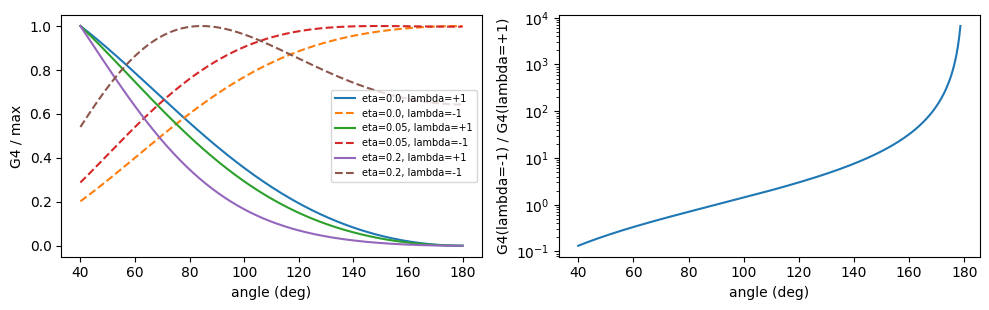

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

**Exercise 4 answer**

**Why the peak moves to about 85°:** For $\lambda=-1$ the angular part $(1-\cos\theta)$ is largest at 180°. But $r_{jk}=2b\sin(\theta/2)$ also gets longer when $\theta$ gets bigger, and is longest (=2b) at 180°. The factor $e^{-\eta r_{jk}^2}$ (and also $f_c(r_{jk})$) becomes small for long $r_{jk}$. With $\eta=0.2$ this damping is strong, so large angles are pushed down. The angular part wants a large angle and the radial part wants a small angle, and the balance gives a maximum near 85° (I get 84° from the data).

**Why the ratio does not depend on $\eta$:** Only the angular part has $\lambda$ in it. The radial part $e^{-\eta(2b^2+r_{jk}^2)}$ and the cutoffs are the same for $\lambda=+1$ and $\lambda=-1$, so they cancel when we divide:
$$\frac{G^4(\lambda=-1)}{G^4(\lambda=+1)}=\left(\frac{1-\cos\theta}{1+\cos\theta}\right)^\zeta=\tan^{2\zeta}(\theta/2)$$
There is no $\eta$ in this, so the ratio only depends on the angle. This is why the angle can be found back from the ratio, as shown in the printed output.